In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
clustering_df = pd.read_csv(
    "India_Tourism_Statistics_2024_Clustering_Cleaned.csv"
)

forecasting_df = pd.read_csv(
    "India_Monthly_FTA_2019_2024.csv"
)

print("Clustering Dataset:", clustering_df.shape)
print("Forecasting Dataset:", forecasting_df.shape)

Clustering Dataset: (209, 7)
Forecasting Dataset: (72, 8)


In [5]:
print("CLUSTERING DATASET")
display(clustering_df.head())

print("\nFORECASTING DATASET")
display(forecasting_df.head())

CLUSTERING DATASET


,Sl. No.,Country/Territory,Arrivals (In Numbers),1st Quarters (January-March) (In Percentage),2nd Quarters (April-June) (In Percentage),3rd Quarters (July-September) (In Percentage),4th Quarters (October-December) (In Percentage)
0,3,Algeria,2522,26.25,19.51,27.00,27.24
1,4,Morocco,9831,23.80,22.70,25.33,28.17
2,5,Sudan,10887,18.20,18.84,33.39,29.58
3,6,Tunisia,5586,27.71,23.06,24.20,25.03
4,8,Angola,1202,23.88,21.80,29.53,24.79



FORECASTING DATASET


,date,year,month,foreign_tourist_arrivals,source_document,source_table,source_organisation,source_url
0,2019-01-01,2019,January,1111040,India Tourism Data Compendium 2025,Table 2.2.1,"Bureau of Immigration, Government of India",https://data.tourism.gov.in/mrd/Uploads/touris...
1,2019-02-01,2019,February,1090516,India Tourism Data Compendium 2025,Table 2.2.1,"Bureau of Immigration, Government of India",https://data.tourism.gov.in/mrd/Uploads/touris...
2,2019-03-01,2019,March,978236,India Tourism Data Compendium 2025,Table 2.2.1,"Bureau of Immigration, Government of India",https://data.tourism.gov.in/mrd/Uploads/touris...
3,2019-04-01,2019,April,774651,India Tourism Data Compendium 2025,Table 2.2.1,"Bureau of Immigration, Government of India",https://data.tourism.gov.in/mrd/Uploads/touris...
4,2019-05-01,2019,May,615136,India Tourism Data Compendium 2025,Table 2.2.1,"Bureau of Immigration, Government of India",https://data.tourism.gov.in/mrd/Uploads/touris...


In [6]:
print("Clustering columns:")
print(clustering_df.columns.tolist())

print("\nClustering missing values:")
print(clustering_df.isnull().sum())

print("\nForecasting columns:")
print(forecasting_df.columns.tolist())

print("\nForecasting missing values:")
print(forecasting_df.isnull().sum())

Clustering columns:
['Sl. No.', 'Country/Territory', 'Arrivals (In Numbers)', '1st Quarters (January-March) (In Percentage)', '2nd Quarters (April-June) (In Percentage)', '3rd Quarters (July-September) (In Percentage)', '4th Quarters (October-December) (In Percentage)']

Clustering missing values:
Sl. No.                                            0
Country/Territory                                  0
Arrivals (In Numbers)                              0
1st Quarters (January-March) (In Percentage)       0
2nd Quarters (April-June) (In Percentage)          0
3rd Quarters (July-September) (In Percentage)      0
4th Quarters (October-December) (In Percentage)    0
dtype: int64

Forecasting columns:
['date', 'year', 'month', 'foreign_tourist_arrivals', 'source_document', 'source_table', 'source_organisation', 'source_url']

Forecasting missing values:
date                        0
year                        0
month                       0
foreign_tourist_arrivals    0
source_document     

In [7]:
print("CLUSTERING DATASET")
print("Shape:", clustering_df.shape)
print("\nData types:")
print(clustering_df.dtypes)

print("\nFORECASTING DATASET")
print("Shape:", forecasting_df.shape)
print("\nData types:")
print(forecasting_df.dtypes)

CLUSTERING DATASET
Shape: (209, 7)

Data types:
Sl. No.                                              int64
Country/Territory                                   object
Arrivals (In Numbers)                                int64
1st Quarters (January-March) (In Percentage)       float64
2nd Quarters (April-June) (In Percentage)          float64
3rd Quarters (July-September) (In Percentage)      float64
4th Quarters (October-December) (In Percentage)    float64
dtype: object

FORECASTING DATASET
Shape: (72, 8)

Data types:
date                        object
year                         int64
month                       object
foreign_tourist_arrivals     int64
source_document             object
source_table                object
source_organisation         object
source_url                  object
dtype: object


In [8]:
quarter_columns = [
    '1st Quarters (January-March) (In Percentage)',
    '2nd Quarters (April-June) (In Percentage)',
    '3rd Quarters (July-September) (In Percentage)',
    '4th Quarters (October-December) (In Percentage)'
]

clustering_df['Quarter_Total'] = clustering_df[
    quarter_columns
].sum(axis=1)

print(clustering_df[
    ['Country/Territory', 'Quarter_Total']
].head(10))

print("\nPercentage validation:")
print("Minimum:", clustering_df['Quarter_Total'].min())
print("Maximum:", clustering_df['Quarter_Total'].max())

print("\nRows outside 99.5–100.5%:")
print(
    clustering_df[
        ~clustering_df['Quarter_Total'].between(99.5, 100.5)
    ][['Country/Territory', 'Quarter_Total']]
)

  Country/Territory  Quarter_Total
0           Algeria         100.00
1           Morocco         100.00
2             Sudan         100.01
3           Tunisia         100.00
4            Angola         100.00
5             Benin         100.00
6          Botswana         100.01
7      Burkina Faso         100.00
8           Burundi         100.00
9          Cameroon          99.99

Percentage validation:
Minimum: 99.98999999999998
Maximum: 100.01000000000002

Rows outside 99.5–100.5%:
Empty DataFrame
Columns: [Country/Territory, Quarter_Total]
Index: []


In [9]:
forecasting_df['date'] = pd.to_datetime(
    forecasting_df['date']
)

forecasting_df = forecasting_df.sort_values('date')

print("First date:", forecasting_df['date'].min())
print("Last date:", forecasting_df['date'].max())

print("Total records:", len(forecasting_df))

print("Duplicate dates:",
      forecasting_df['date'].duplicated().sum())

expected_dates = pd.date_range(
    start=forecasting_df['date'].min(),
    end=forecasting_df['date'].max(),
    freq='MS'
)

missing_dates = expected_dates.difference(
    forecasting_df['date']
)

print("Missing months:", list(missing_dates))

First date: 2019-01-01 00:00:00
Last date: 2024-12-01 00:00:00
Total records: 72
Duplicate dates: 0
Missing months: []


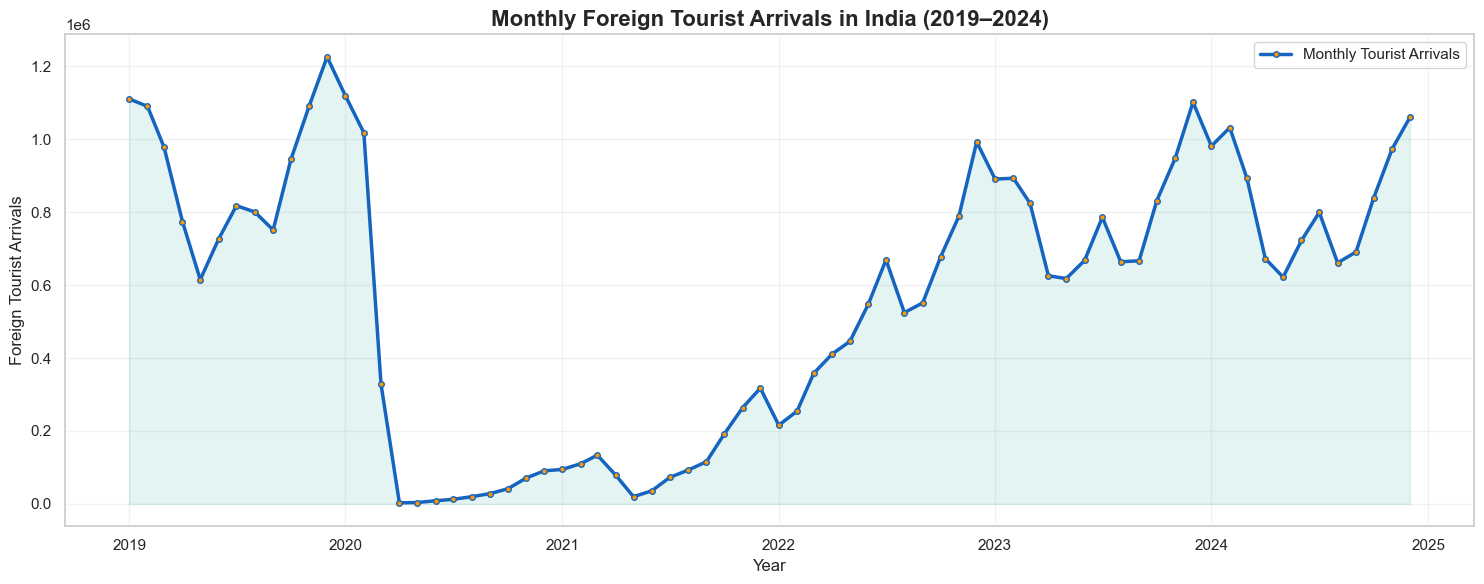

In [16]:
plt.figure(figsize=(15, 6))

plt.plot(
    forecasting_df['date'],
    forecasting_df['foreign_tourist_arrivals'],
    color='#1565C0',
    linewidth=2.5,
    marker='o',
    markersize=4,
    markerfacecolor='#FF9800',
    label='Monthly Tourist Arrivals'
)

plt.fill_between(
    forecasting_df['date'],
    forecasting_df['foreign_tourist_arrivals'],
    alpha=0.12,
    color='#26A69A'
)

plt.title(
    'Monthly Foreign Tourist Arrivals in India (2019–2024)',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Year', fontsize=12)
plt.ylabel('Foreign Tourist Arrivals', fontsize=12)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [11]:
features = [
    'Arrivals (In Numbers)',
    '1st Quarters (January-March) (In Percentage)',
    '2nd Quarters (April-June) (In Percentage)',
    '3rd Quarters (July-September) (In Percentage)',
    '4th Quarters (October-December) (In Percentage)'
]

X = clustering_df[features].copy()

print("Selected features:")
print(X.head())

print("\nFeature shape:", X.shape)

Selected features:
   Arrivals (In Numbers)  1st Quarters (January-March) (In Percentage)  \
0                   2522                                         26.25   
1                   9831                                         23.80   
2                  10887                                         18.20   
3                   5586                                         27.71   
4                   1202                                         23.88   

   2nd Quarters (April-June) (In Percentage)  \
0                                      19.51   
1                                      22.70   
2                                      18.84   
3                                      23.06   
4                                      21.80   

   3rd Quarters (July-September) (In Percentage)  \
0                                          27.00   
1                                          25.33   
2                                          33.39   
3                                      

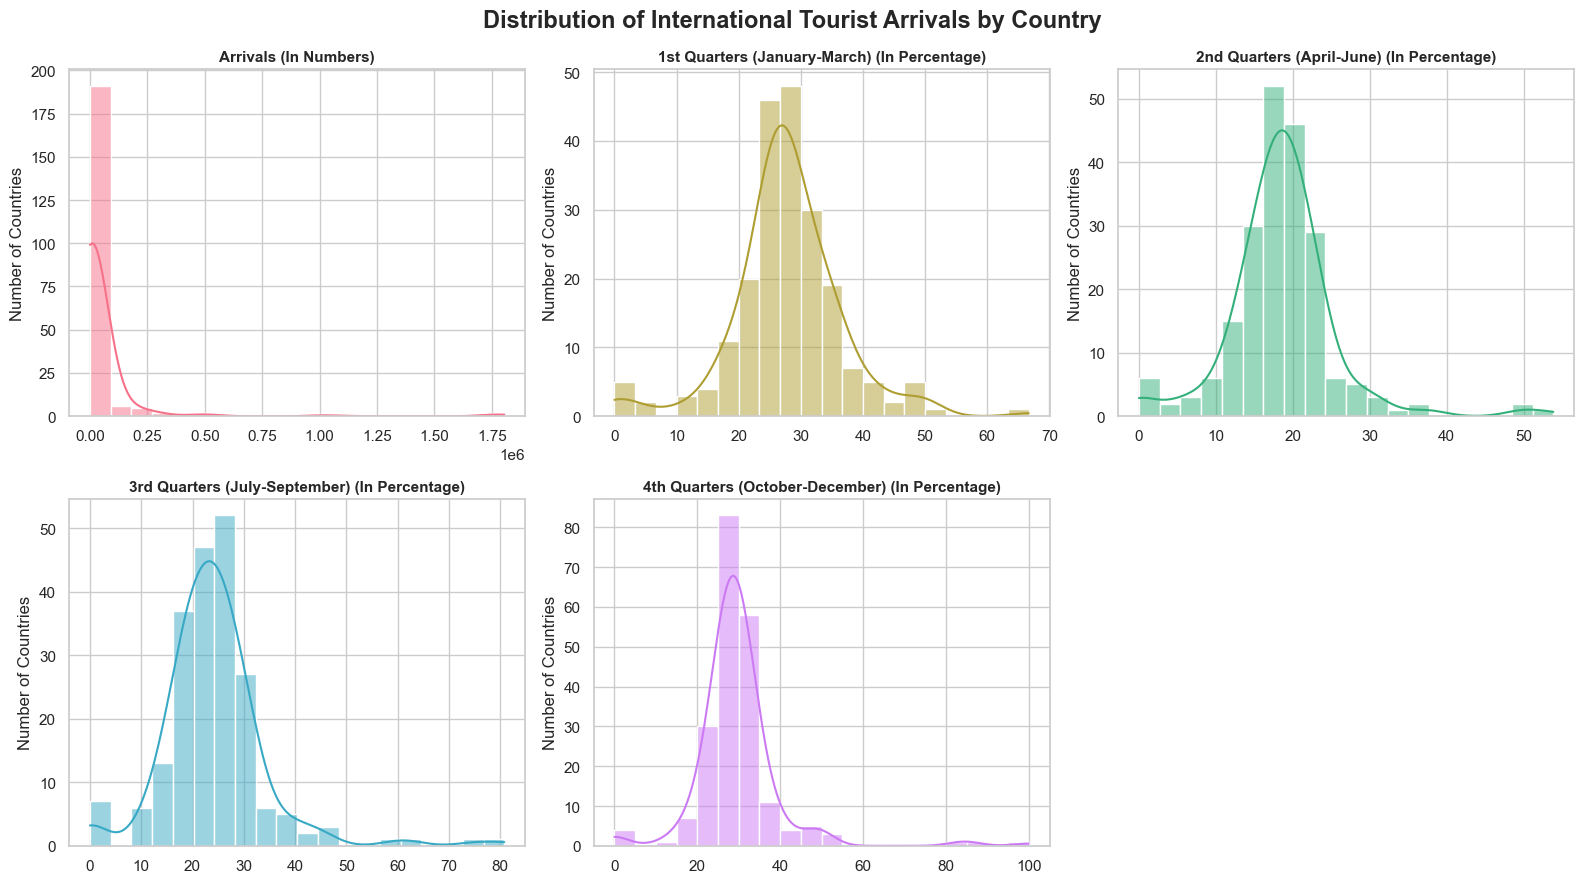

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")

colors = sns.color_palette("husl", 5)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, column in enumerate(features):
    ax = axes[i // 3, i % 3]

    sns.histplot(
        data=X,
        x=column,
        bins=20,
        kde=True,
        color=colors[i],
        edgecolor="white",
        ax=ax
    )

    ax.set_title(column, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Number of Countries")

axes[1, 2].axis("off")

plt.suptitle(
    "Distribution of International Tourist Arrivals by Country",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

print(X_scaled_df.head())

print("\nMean after scaling:")
print(X_scaled_df.mean().round(3))

print("\nStandard deviation after scaling:")
print(X_scaled_df.std().round(3))

   Arrivals (In Numbers)  1st Quarters (January-March) (In Percentage)  \
0              -0.230762                                     -0.168781   
1              -0.193325                                     -0.444747   
2              -0.187917                                     -1.075527   
3              -0.215068                                     -0.004328   
4              -0.237523                                     -0.435736   

   2nd Quarters (April-June) (In Percentage)  \
0                                   0.137821   
1                                   0.589820   
2                                   0.042887   
3                                   0.640829   
4                                   0.462297   

   3rd Quarters (July-September) (In Percentage)  \
0                                       0.290110   
1                                       0.125000   
2                                       0.921878   
3                                       0.013279   
4     

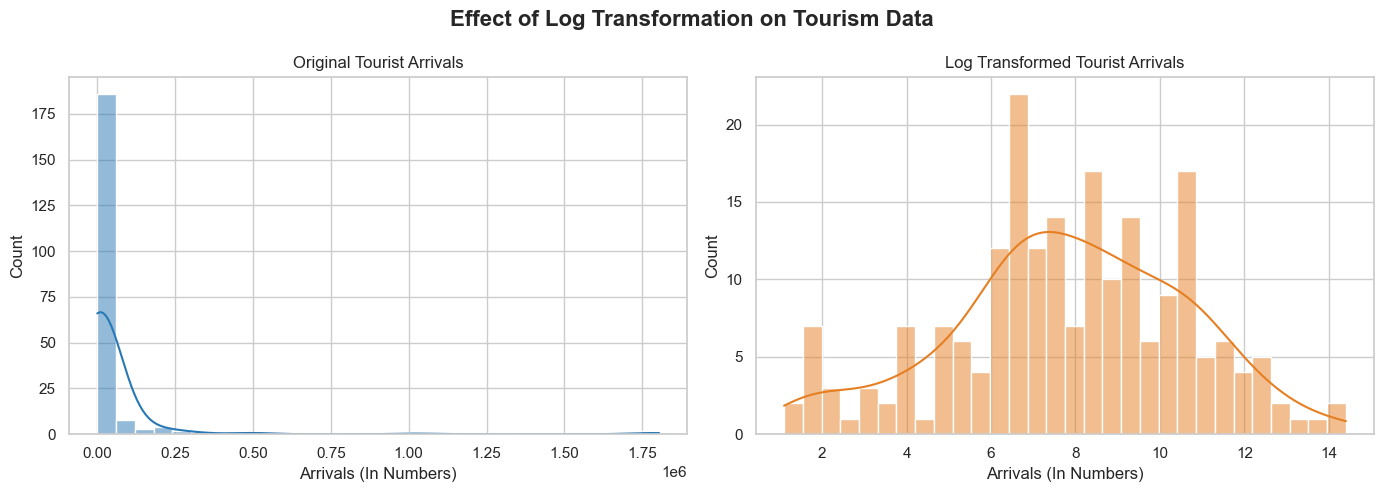

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    X['Arrivals (In Numbers)'],
    bins=30,
    kde=True,
    color='#2878B5',
    ax=axes[0]
)

axes[0].set_title('Original Tourist Arrivals')

log_arrivals = np.log1p(X['Arrivals (In Numbers)'])

sns.histplot(
    log_arrivals,
    bins=30,
    kde=True,
    color='#E67E22',
    ax=axes[1]
)

axes[1].set_title('Log Transformed Tourist Arrivals')

plt.suptitle(
    'Effect of Log Transformation on Tourism Data',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [19]:
print("Original arrivals skewness:",
      X['Arrivals (In Numbers)'].skew())

print("Log transformed skewness:",
      log_arrivals.skew())

Original arrivals skewness: 7.455724469316376
Log transformed skewness: -0.25051059553532606


In [20]:
X_log = X.copy()

X_log['Arrivals (In Numbers)'] = np.log1p(
    X_log['Arrivals (In Numbers)']
)

scaler_log = StandardScaler()

X_log_scaled = scaler_log.fit_transform(X_log)

print("Log transformed dataset shape:",
      X_log_scaled.shape)

print("Mean:", np.round(X_log_scaled.mean(axis=0), 3))

print("Standard deviation:",
      np.round(X_log_scaled.std(axis=0), 3))

Log transformed dataset shape: (209, 5)
Mean: [-0.  0. -0.  0.  0.]
Standard deviation: [1. 1. 1. 1. 1.]


In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)

results = {
    "Original": {"inertia": [], "silhouette": []},
    "Log Transformed": {"inertia": [], "silhouette": []}
}

datasets = {
    "Original": X_scaled,
    "Log Transformed": X_log_scaled
}

for name, data in datasets.items():

    for k in k_values:

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        labels = model.fit_predict(data)

        results[name]["inertia"].append(model.inertia_)

        score = silhouette_score(data, labels)

        results[name]["silhouette"].append(score)

    print(f"{name} evaluation completed!")

Original evaluation completed!
Log Transformed evaluation completed!


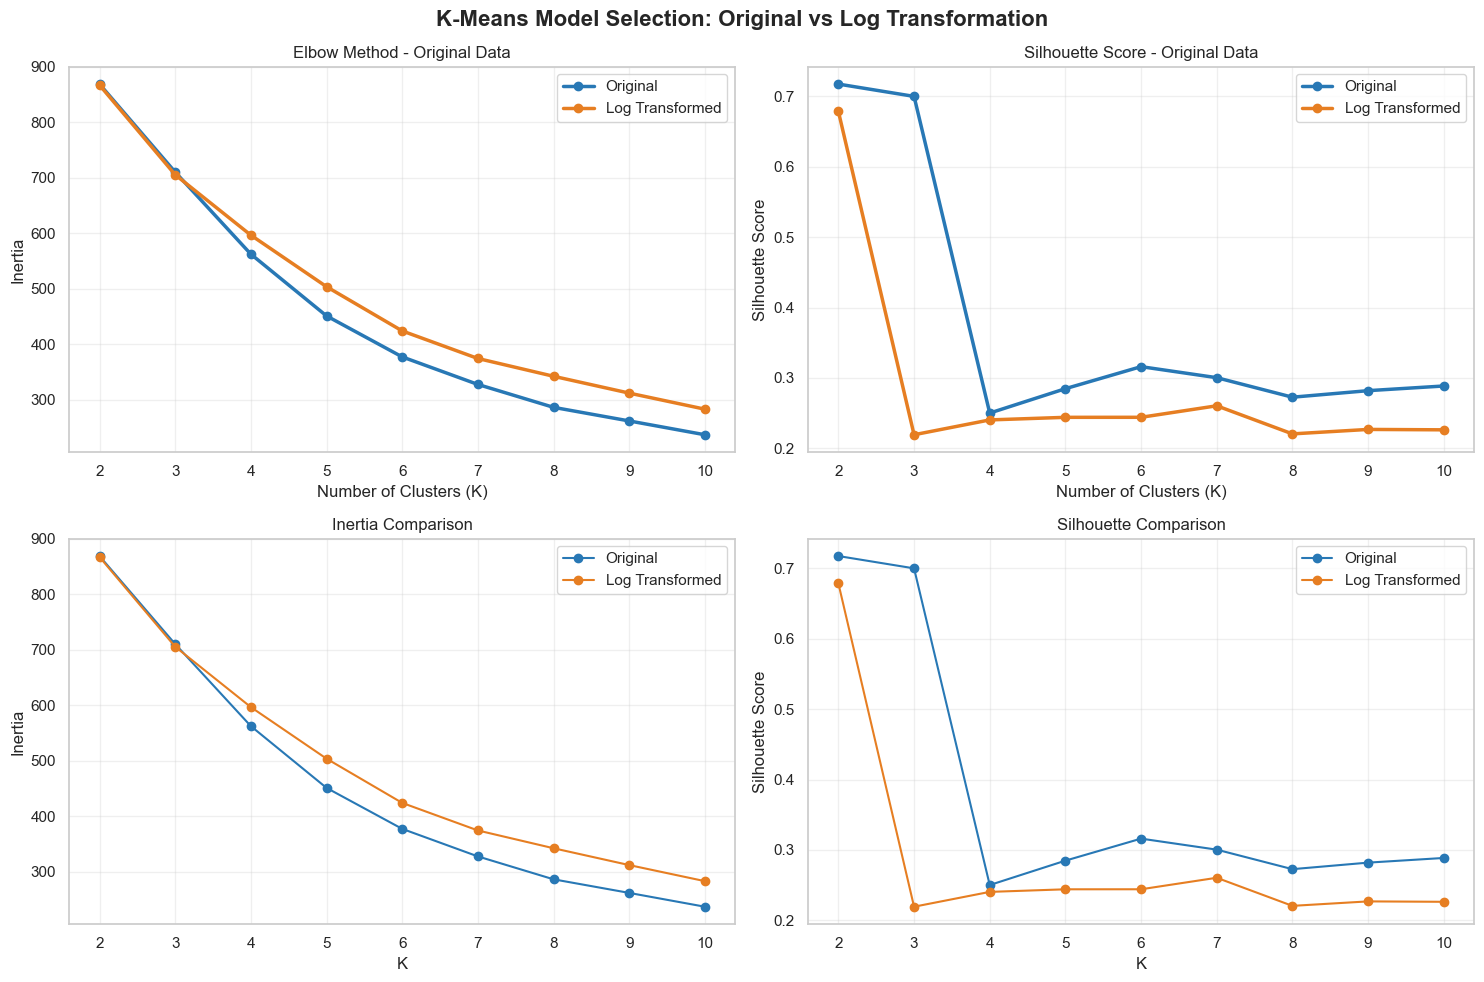

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

colors = {
    "Original": "#2878B5",
    "Log Transformed": "#E67E22"
}

for name in datasets:

    axes[0, 0].plot(
        list(k_values),
        results[name]["inertia"],
        marker="o",
        linewidth=2.5,
        color=colors[name],
        label=name
    )

    axes[0, 1].plot(
        list(k_values),
        results[name]["silhouette"],
        marker="o",
        linewidth=2.5,
        color=colors[name],
        label=name
    )

axes[0, 0].set_title("Elbow Method - Original Data")
axes[0, 1].set_title("Silhouette Score - Original Data")

axes[0, 0].set_ylabel("Inertia")
axes[0, 1].set_ylabel("Silhouette Score")

axes[0, 0].set_xlabel("Number of Clusters (K)")
axes[0, 1].set_xlabel("Number of Clusters (K)")

# Separate comparison plots
for name in datasets:

    axes[1, 0].plot(
        list(k_values),
        results[name]["inertia"],
        marker="o",
        color=colors[name],
        label=name
    )

    axes[1, 1].plot(
        list(k_values),
        results[name]["silhouette"],
        marker="o",
        color=colors[name],
        label=name
    )

axes[1, 0].set_title("Inertia Comparison")
axes[1, 1].set_title("Silhouette Comparison")

axes[1, 0].set_xlabel("K")
axes[1, 1].set_xlabel("K")

axes[1, 0].set_ylabel("Inertia")
axes[1, 1].set_ylabel("Silhouette Score")

for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "K-Means Model Selection: Original vs Log Transformation",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [23]:
comparison = pd.DataFrame({
    "K": list(k_values),
    "Original Inertia": results["Original"]["inertia"],
    "Original Silhouette": results["Original"]["silhouette"],
    "Log Inertia": results["Log Transformed"]["inertia"],
    "Log Silhouette": results["Log Transformed"]["silhouette"]
})

display(comparison.round(4))

,K,Original Inertia,Original Silhouette,Log Inertia,Log Silhouette
0,2,869.1466,0.7175,867.3887,0.6786
1,3,710.4720,0.7001,705.6746,0.2193
2,4,562.4977,0.2501,596.7538,0.2403
3,5,451.1375,0.2847,503.8098,0.2440
4,6,377.2362,0.3160,424.0600,0.2441
5,7,327.5667,0.3004,374.3632,0.2604
6,8,286.2737,0.2726,342.2951,0.2205
7,9,261.7450,0.2819,311.9316,0.2268
8,10,236.8490,0.2885,282.9549,0.2263


In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples

diagnostics = {}

for name, data in datasets.items():

    for k in [2, 3]:

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=50
        )

        labels = model.fit_predict(data)

        diagnostics[(name, k)] = labels

        print(f"\n{'='*45}")
        print(f"{name} | K = {k}")
        print(f"{'='*45}")

        print("\nCluster sizes:")
        print(pd.Series(labels).value_counts().sort_index())

        print("\nAverage silhouette by cluster:")

        sample_scores = silhouette_samples(data, labels)

        for cluster in range(k):
            cluster_scores = sample_scores[labels == cluster]

            print(
                f"Cluster {cluster}: "
                f"{cluster_scores.mean():.4f}"
            )

        profile = clustering_df.copy()
        profile['Cluster'] = labels

        print("\nCluster profiles (original units):")

        display(
            profile.groupby('Cluster')[features]
            .mean()
            .round(2)
        )


Original | K = 2

Cluster sizes:
0    206
1      3
Name: count, dtype: int64

Average silhouette by cluster:
Cluster 0: 0.7207
Cluster 1: 0.4993

Cluster profiles (original units):


,Arrivals (In Numbers),1st Quarters (January-March) (In Percentage),2nd Quarters (April-June) (In Percentage),3rd Quarters (July-September) (In Percentage),4th Quarters (October-December) (In Percentage)
Cluster,,,,,
0,26048.25,27.72,18.49,24.11,29.69
1,1525779.33,30.01,21.94,21.04,27.01



Original | K = 3

Cluster sizes:
0    202
1      4
2      3
Name: count, dtype: int64

Average silhouette by cluster:
Cluster 0: 0.7093
Cluster 1: 0.3874
Cluster 2: 0.4949

Cluster profiles (original units):


,Arrivals (In Numbers),1st Quarters (January-March) (In Percentage),2nd Quarters (April-June) (In Percentage),3rd Quarters (July-September) (In Percentage),4th Quarters (October-December) (In Percentage)
Cluster,,,,,
0,26563.96,28.26,18.45,24.59,28.70
1,5.25,0.00,20.24,0.00,79.76
2,1525779.33,30.01,21.94,21.04,27.01



Log Transformed | K = 2

Cluster sizes:
0    205
1      4
Name: count, dtype: int64

Average silhouette by cluster:
Cluster 0: 0.6837
Cluster 1: 0.4197

Cluster profiles (original units):


,Arrivals (In Numbers),1st Quarters (January-March) (In Percentage),2nd Quarters (April-June) (In Percentage),3rd Quarters (July-September) (In Percentage),4th Quarters (October-December) (In Percentage)
Cluster,,,,,
0,48503.69,28.29,18.50,24.54,28.67
1,5.25,0.00,20.24,0.00,79.76



Log Transformed | K = 3

Cluster sizes:
0    109
1      4
2     96
Name: count, dtype: int64

Average silhouette by cluster:
Cluster 0: 0.2835
Cluster 1: 0.4082
Cluster 2: 0.1384

Cluster profiles (original units):


,Arrivals (In Numbers),1st Quarters (January-March) (In Percentage),2nd Quarters (April-June) (In Percentage),3rd Quarters (July-September) (In Percentage),4th Quarters (October-December) (In Percentage)
Cluster,,,,,
0,85939.32,32.86,17.72,19.59,29.83
1,5.25,0.00,20.24,0.00,79.76
2,5998.66,23.11,19.39,30.15,27.35


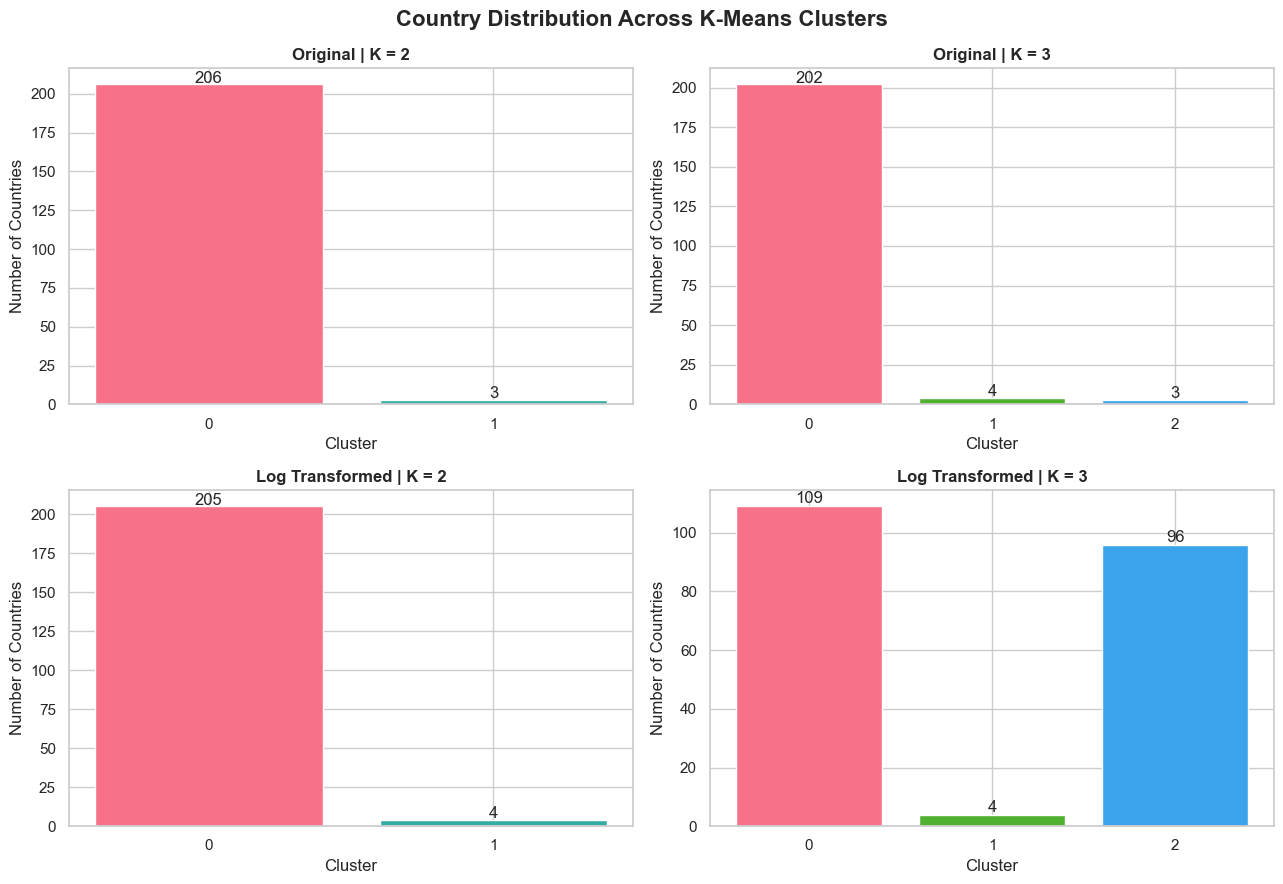

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

plot_number = 0

for name in datasets:

    for k in [2, 3]:

        ax = axes.flat[plot_number]

        labels = diagnostics[(name, k)]

        counts = pd.Series(labels).value_counts().sort_index()

        ax.bar(
            counts.index.astype(str),
            counts.values,
            color=sns.color_palette("husl", k),
            edgecolor="white"
        )

        ax.set_title(
            f"{name} | K = {k}",
            fontweight="bold"
        )

        ax.set_xlabel("Cluster")
        ax.set_ylabel("Number of Countries")

        for i, value in enumerate(counts.values):
            ax.text(i, value + 1, str(value), ha="center")

        plot_number += 1

plt.suptitle(
    "Country Distribution Across K-Means Clusters",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [26]:
final_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=50
)

clustering_df['Cluster'] = final_model.fit_predict(X_scaled)

for cluster in sorted(clustering_df['Cluster'].unique()):
    print(f"\nCLUSTER {cluster}")

    display(
        clustering_df.loc[
            clustering_df['Cluster'] == cluster,
            ['Country/Territory', 'Arrivals (In Numbers)']
        ].sort_values(
            by='Arrivals (In Numbers)',
            ascending=False
        )
    )


CLUSTER 0


,Country/Territory,Arrivals (In Numbers)
104,Australia,518205
79,Canada,476273
133,Malaysia,307526
128,Sri Lanka,281827
189,Germany,256348
...,...,...
53,Anguilla,4
58,Brit. Virgin Islands,4
71,Turks and Caicos,4
112,New Caledonia,3



CLUSTER 1


,Country/Territory,Arrivals (In Numbers)
81,United States,1804586
122,Bangladesh,1750165
167,United Kingdom,1022587


In [27]:
model_k3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=50
)

clustering_df['Cluster_K3'] = model_k3.fit_predict(X_scaled)

for cluster in sorted(clustering_df['Cluster_K3'].unique()):

    print(f"\n{'='*50}")
    print(f"CLUSTER {cluster}")
    print(f"{'='*50}")

    display(
        clustering_df.loc[
            clustering_df['Cluster_K3'] == cluster,
            ['Country/Territory', 'Arrivals (In Numbers)']
        ].sort_values(
            by='Arrivals (In Numbers)',
            ascending=False
        )
    )


CLUSTER 0


,Country/Territory,Arrivals (In Numbers)
104,Australia,518205
79,Canada,476273
133,Malaysia,307526
128,Sri Lanka,281827
189,Germany,256348
...,...,...
71,Turks and Caicos,4
58,Brit. Virgin Islands,4
53,Anguilla,4
112,New Caledonia,3



CLUSTER 1


,Country/Territory,Arrivals (In Numbers)
103,American Samoa,7
66,Neth. Antilles,6
55,Aruba,4
107,French Polynesia,4



CLUSTER 2


,Country/Territory,Arrivals (In Numbers)
81,United States,1804586
122,Bangladesh,1750165
167,United Kingdom,1022587


,Number_of_Countries,Average_Arrivals,Minimum_Arrivals,Maximum_Arrivals
Cluster,,,,
0,206,26048.25,2,518205
1,3,1525779.33,1022587,1804586


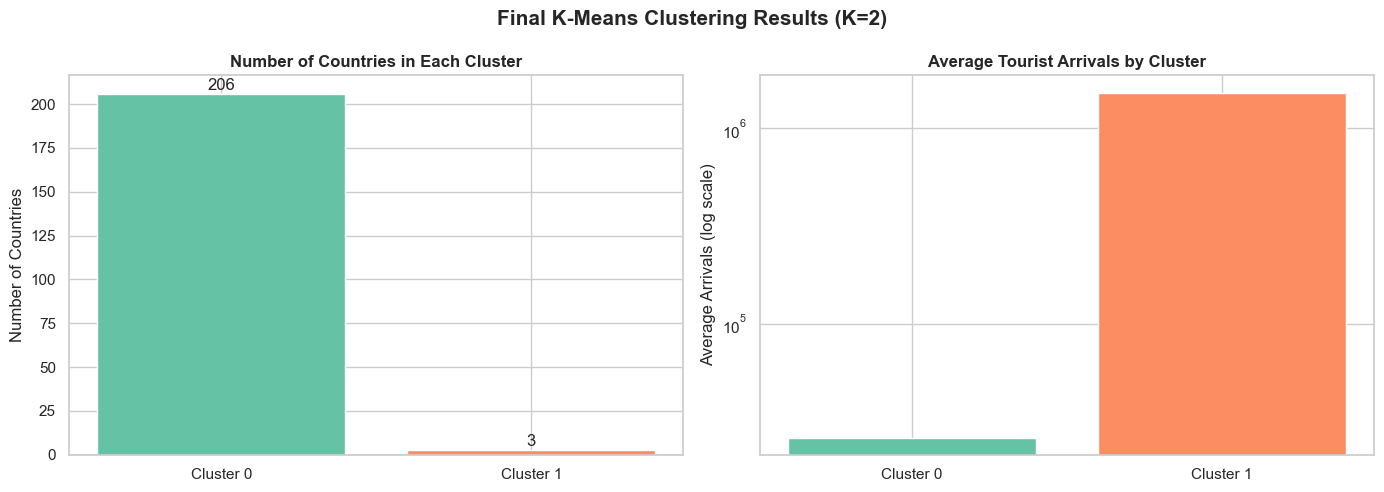

In [28]:
# Final clustering summary
final_summary = clustering_df.groupby('Cluster').agg(
    Number_of_Countries=('Country/Territory', 'count'),
    Average_Arrivals=('Arrivals (In Numbers)', 'mean'),
    Minimum_Arrivals=('Arrivals (In Numbers)', 'min'),
    Maximum_Arrivals=('Arrivals (In Numbers)', 'max')
).round(2)

display(final_summary)

# Visualize cluster sizes and average arrivals
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = sns.color_palette("Set2", 2)

# Cluster sizes
counts = clustering_df['Cluster'].value_counts().sort_index()

axes[0].bar(
    ['Cluster 0', 'Cluster 1'],
    counts.values,
    color=colors,
    edgecolor='white'
)

axes[0].set_title('Number of Countries in Each Cluster', fontweight='bold')
axes[0].set_ylabel('Number of Countries')

for i, value in enumerate(counts.values):
    axes[0].text(i, value + 2, str(value), ha='center')

# Average arrivals (log scale helps show the difference)
averages = clustering_df.groupby('Cluster')['Arrivals (In Numbers)'].mean()

axes[1].bar(
    ['Cluster 0', 'Cluster 1'],
    averages.values,
    color=colors,
    edgecolor='white'
)

axes[1].set_title('Average Tourist Arrivals by Cluster', fontweight='bold')
axes[1].set_ylabel('Average Arrivals (log scale)')
axes[1].set_yscale('log')

plt.suptitle('Final K-Means Clustering Results (K=2)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [29]:
import os

os.makedirs("../outputs", exist_ok=True)

clustering_df.to_csv(
    "../outputs/final_clustering_results.csv",
    index=False
)

print("Clustering results saved successfully!")

Clustering results saved successfully!


# Monthly Tourism Forcasting 

In [31]:
# Prepare monthly time-series data

forecasting_df['date'] = pd.to_datetime(forecasting_df['date'])

forecasting_df = forecasting_df.sort_values('date')

ts = forecasting_df.set_index('date')['foreign_tourist_arrivals']
ts = ts.asfreq('MS')

print("First observation:", ts.index.min())
print("Last observation:", ts.index.max())
print("Total observations:", len(ts))
print("Missing values:", ts.isnull().sum())

display(forecasting_df.head())

First observation: 2019-01-01 00:00:00
Last observation: 2024-12-01 00:00:00
Total observations: 72
Missing values: 0


,date,year,month,foreign_tourist_arrivals,source_document,source_table,source_organisation,source_url
0,2019-01-01,2019,January,1111040,India Tourism Data Compendium 2025,Table 2.2.1,"Bureau of Immigration, Government of India",https://data.tourism.gov.in/mrd/Uploads/touris...
1,2019-02-01,2019,February,1090516,India Tourism Data Compendium 2025,Table 2.2.1,"Bureau of Immigration, Government of India",https://data.tourism.gov.in/mrd/Uploads/touris...
2,2019-03-01,2019,March,978236,India Tourism Data Compendium 2025,Table 2.2.1,"Bureau of Immigration, Government of India",https://data.tourism.gov.in/mrd/Uploads/touris...
3,2019-04-01,2019,April,774651,India Tourism Data Compendium 2025,Table 2.2.1,"Bureau of Immigration, Government of India",https://data.tourism.gov.in/mrd/Uploads/touris...
4,2019-05-01,2019,May,615136,India Tourism Data Compendium 2025,Table 2.2.1,"Bureau of Immigration, Government of India",https://data.tourism.gov.in/mrd/Uploads/touris...


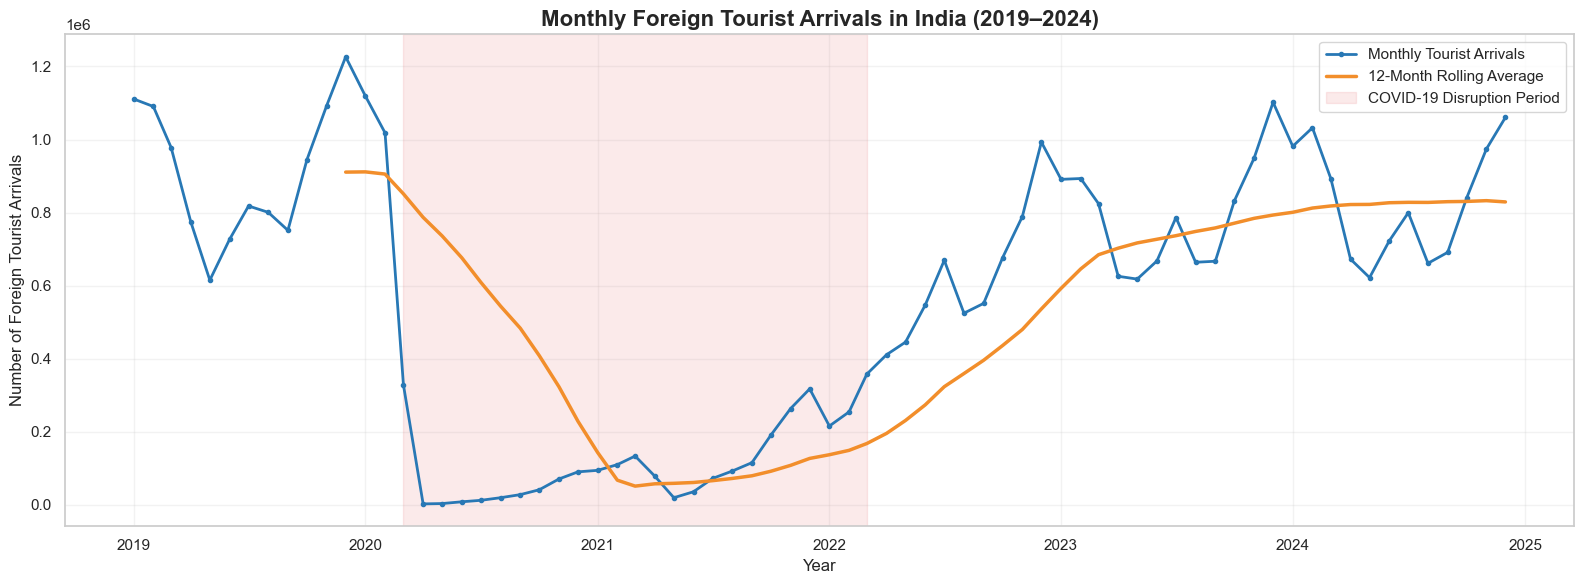

In [32]:
# Monthly Foreign Tourist Arrivals in India (2019–2024)

plt.figure(figsize=(16, 6))

plt.plot(
    ts.index,
    ts.values,
    color="#2878B5",
    linewidth=2,
    marker="o",
    markersize=3,
    label="Monthly Tourist Arrivals"
)

# 12-month rolling average
rolling_avg = ts.rolling(window=12).mean()

plt.plot(
    rolling_avg.index,
    rolling_avg.values,
    color="#F28E2B",
    linewidth=2.5,
    label="12-Month Rolling Average"
)

# Highlight COVID disruption period
plt.axvspan(
    pd.Timestamp("2020-03-01"),
    pd.Timestamp("2022-03-01"),
    color="#E15759",
    alpha=0.12,
    label="COVID-19 Disruption Period"
)

plt.title(
    "Monthly Foreign Tourist Arrivals in India (2019–2024)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Number of Foreign Tourist Arrivals", fontsize=12)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [34]:
# print("Monthly Tourism Trend Summary")
# print("--------------------------------")

# print("Minimum arrivals:", ts.min())
# print("Maximum arrivals:", ts.max())
# print("Average arrivals:", round(ts.mean(), 2))

# print("\nYear-wise average arrivals:")
# print(ts.resample('YE').mean())

# print("\nYear-wise total arrivals:")
# print(ts.resample('YE').sum())

# print("\nRolling average:")
# print(ts.rolling(window=12).mean().dropna().head())


In [35]:
# Create a copy for seasonality analysis
seasonality_df = forecasting_df.copy()

# Extract year and month
seasonality_df['year'] = seasonality_df['date'].dt.year
seasonality_df['month'] = seasonality_df['date'].dt.month

# Calculate average arrivals for each month
monthly_seasonality = (
    seasonality_df
    .groupby('month')['foreign_tourist_arrivals']
    .mean()
)

print("Average Tourist Arrivals by Month")
print(monthly_seasonality)

Average Tourist Arrivals by Month
month
1     735596.666667
2     733243.166667
3     585983.500000
4     427609.166667
5     387438.333333
6     451419.166667
7     526518.000000
8     460593.166667
9     467519.000000
10    587924.000000
11    689864.333333
12    798350.166667
Name: foreign_tourist_arrivals, dtype: float64


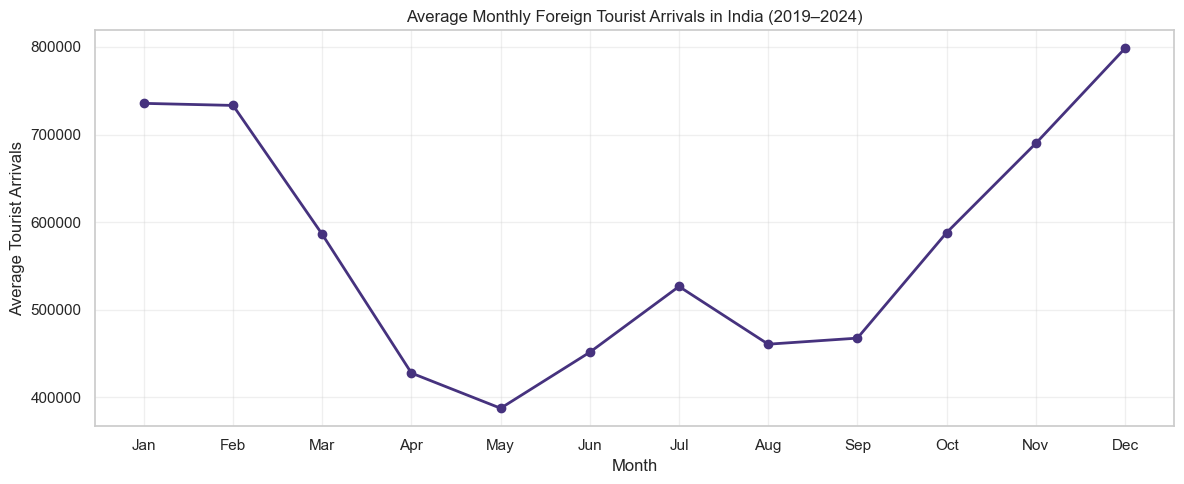

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_seasonality.index,
    monthly_seasonality.values,
    marker='o',
    linewidth=2
)

plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.title('Average Monthly Foreign Tourist Arrivals in India (2019–2024)')
plt.xlabel('Month')
plt.ylabel('Average Tourist Arrivals')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

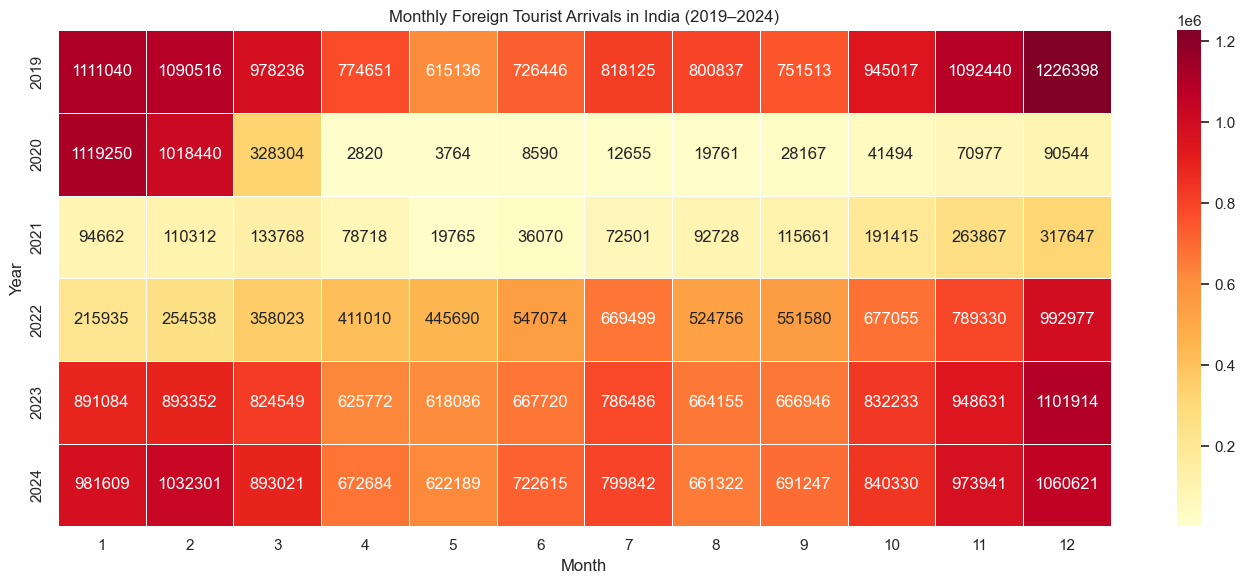

In [37]:
import seaborn as sns

monthly_data = seasonality_df.pivot(
    index='year',
    columns='month',
    values='foreign_tourist_arrivals'
)

plt.figure(figsize=(14, 6))

sns.heatmap(
    monthly_data,
    cmap='YlOrRd',
    annot=True,
    fmt='.0f',
    linewidths=0.5
)

plt.title('Monthly Foreign Tourist Arrivals in India (2019–2024)')
plt.xlabel('Month')
plt.ylabel('Year')

plt.tight_layout()
plt.show()

In [38]:
seasonality_df['yearly_average'] = (
    seasonality_df.groupby('year')['foreign_tourist_arrivals']
    .transform('mean')
)

seasonality_df['seasonality_index'] = (
    seasonality_df['foreign_tourist_arrivals'] /
    seasonality_df['yearly_average']
) * 100

seasonality_index = (
    seasonality_df.groupby('month')['seasonality_index']
    .mean()
)

print("Seasonality Index:")
print(seasonality_index.round(2))

Seasonality Index:
month
1     159.44
2     156.03
3     105.73
4      64.12
5      53.45
6      64.19
7      78.78
8      71.78
9      75.99
10    100.79
11    123.74
12    145.95
Name: seasonality_index, dtype: float64


## Calculating the covid 19 impact

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate yearly average arrivals
yearly_avg = forecasting_df.groupby(
    forecasting_df['date'].dt.year
)['foreign_tourist_arrivals'].mean()

# Calculate percentage change against 2019
baseline_2019 = yearly_avg.loc[2019]

covid_impact = pd.DataFrame({
    'Average Arrivals': yearly_avg,
    'Change from 2019 (%)':
        ((yearly_avg / baseline_2019) - 1) * 100
})

print(covid_impact.round(2))

      Average Arrivals  Change from 2019 (%)
date                                        
2019         910862.92                  0.00
2020         228730.50                -74.89
2021         127259.50                -86.03
2022         536455.58                -41.10
2023         793410.67                -12.89
2024         829310.17                 -8.95


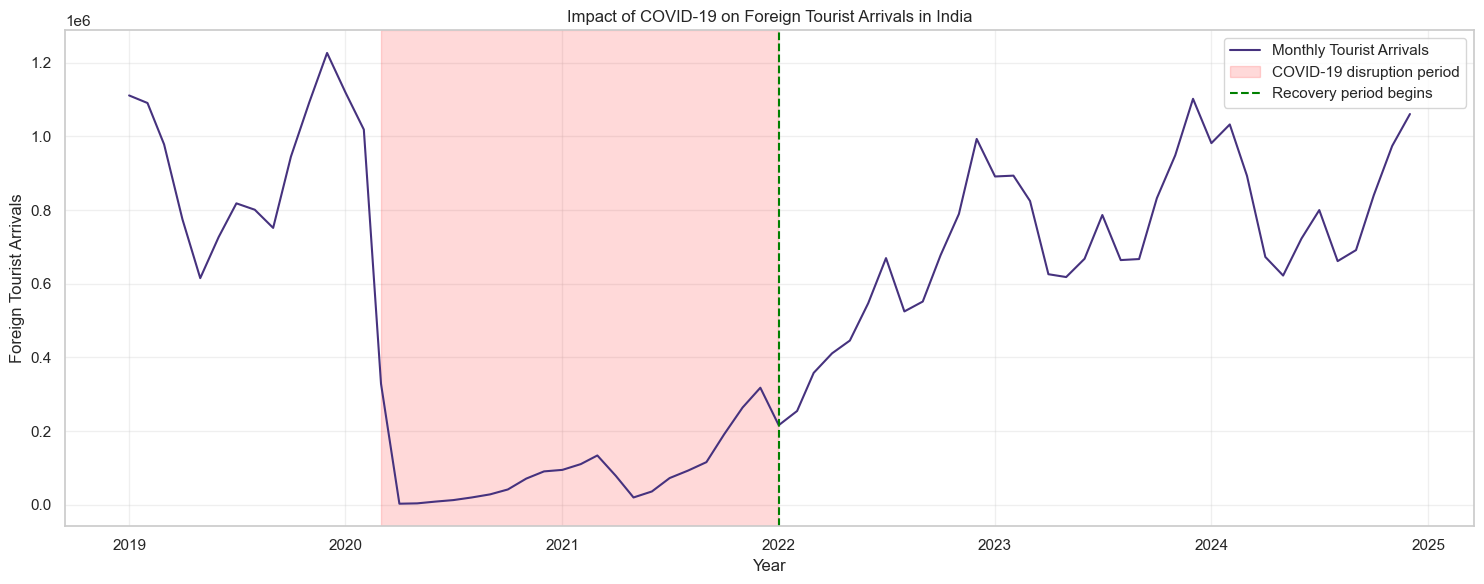

In [40]:
plt.figure(figsize=(15, 6))

plt.plot(
    ts.index,
    ts.values,
    label='Monthly Tourist Arrivals',
    linewidth=1.5
)

plt.axvspan(
    pd.Timestamp('2020-03-01'),
    pd.Timestamp('2021-12-31'),
    color='red',
    alpha=0.15,
    label='COVID-19 disruption period'
)

plt.axvline(
    pd.Timestamp('2022-01-01'),
    color='green',
    linestyle='--',
    label='Recovery period begins'
)

plt.title('Impact of COVID-19 on Foreign Tourist Arrivals in India')
plt.xlabel('Year')
plt.ylabel('Foreign Tourist Arrivals')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
# Chronological train-test split

train = ts.loc[:'2023-12-01']
test = ts.loc['2024-01-01':]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 60
Testing observations: 12

Training period:
2019-01-01 00:00:00 to 2023-12-01 00:00:00

Testing period:
2024-01-01 00:00:00 to 2024-12-01 00:00:00


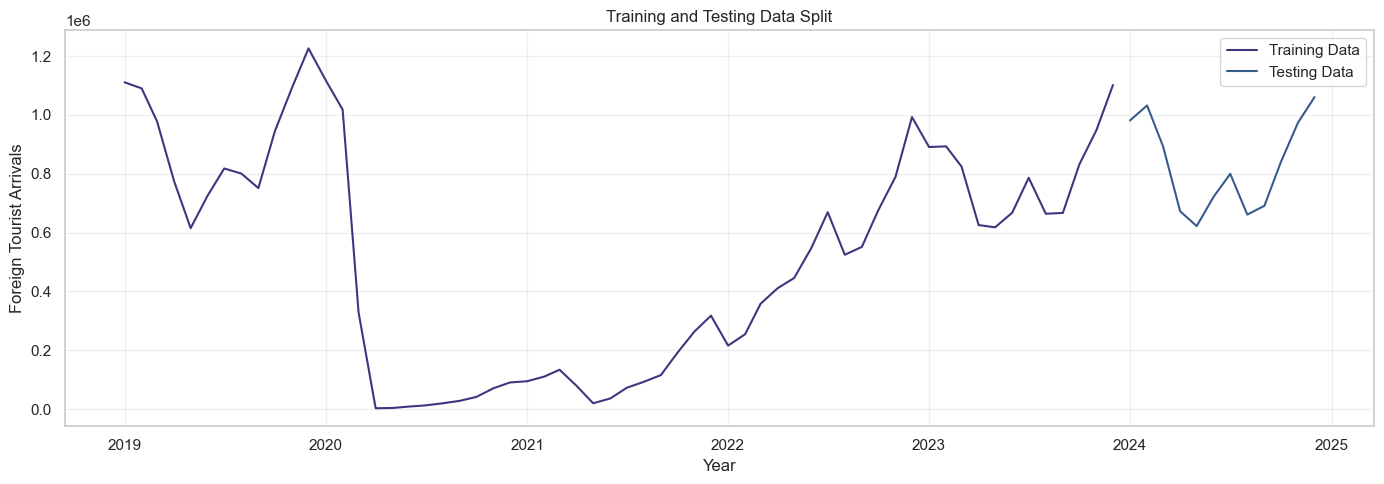

In [42]:
plt.figure(figsize=(14, 5))

plt.plot(train, label='Training Data')
plt.plot(test, label='Testing Data')

plt.title('Training and Testing Data Split')
plt.xlabel('Year')
plt.ylabel('Foreign Tourist Arrivals')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
from statsmodels.tsa.stattools import adfuller

# Perform ADF test on training data
adf_result = adfuller(train)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value}")

if adf_result[1] <= 0.05:
    print("\nConclusion: Data is Stationary")
else:
    print("\nConclusion: Data is Non-Stationary")

ADF Statistic: -2.130191638028692
p-value: 0.23254893035178353

Critical Values:
1%: -3.548493559596539
5%: -2.912836594776334
10%: -2.594129155766944

Conclusion: Data is Non-Stationary


Original observations: 60
Differenced observations: 59


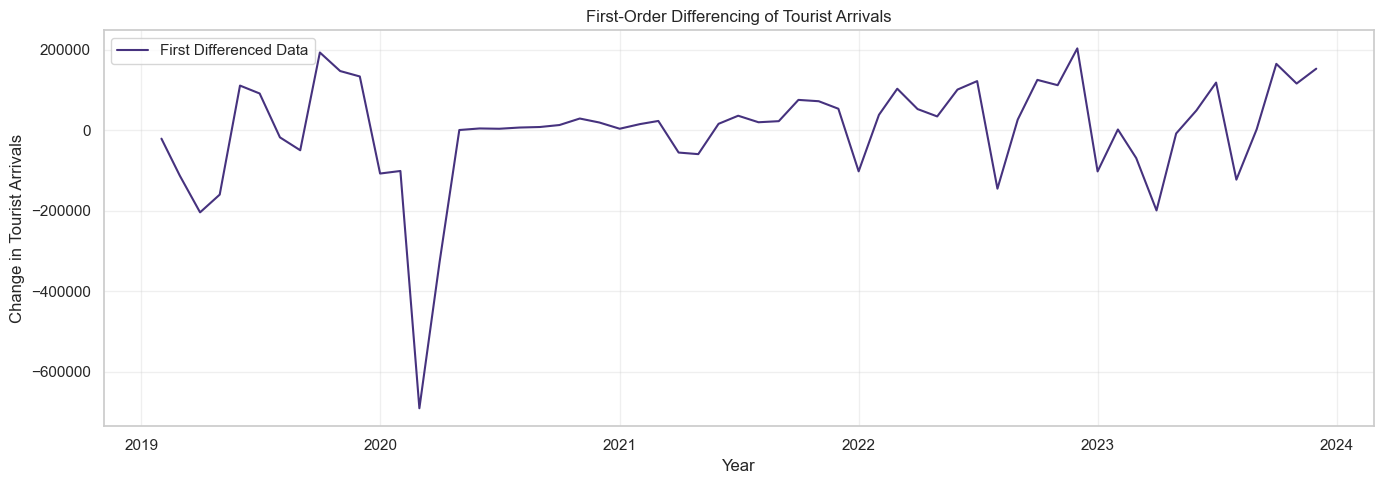

In [44]:
# First-order differencing
train_diff = train.diff().dropna()

print("Original observations:", len(train))
print("Differenced observations:", len(train_diff))

# Visualize differenced data
plt.figure(figsize=(14, 5))

plt.plot(train_diff, label='First Differenced Data')

plt.title('First-Order Differencing of Tourist Arrivals')
plt.xlabel('Year')
plt.ylabel('Change in Tourist Arrivals')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
adf_diff = adfuller(train_diff)

print("ADF Statistic:", adf_diff[0])
print("p-value:", adf_diff[1])

print("\nCritical Values:")
for key, value in adf_diff[4].items():
    print(f"{key}: {value}")

if adf_diff[1] <= 0.05:
    print("\nConclusion: Differenced data is Stationary")
else:
    print("\nConclusion: Differenced data is Non-Stationary")

ADF Statistic: -4.723730299010898
p-value: 7.592635096437489e-05

Critical Values:
1%: -3.548493559596539
5%: -2.912836594776334
10%: -2.594129155766944

Conclusion: Differenced data is Stationary


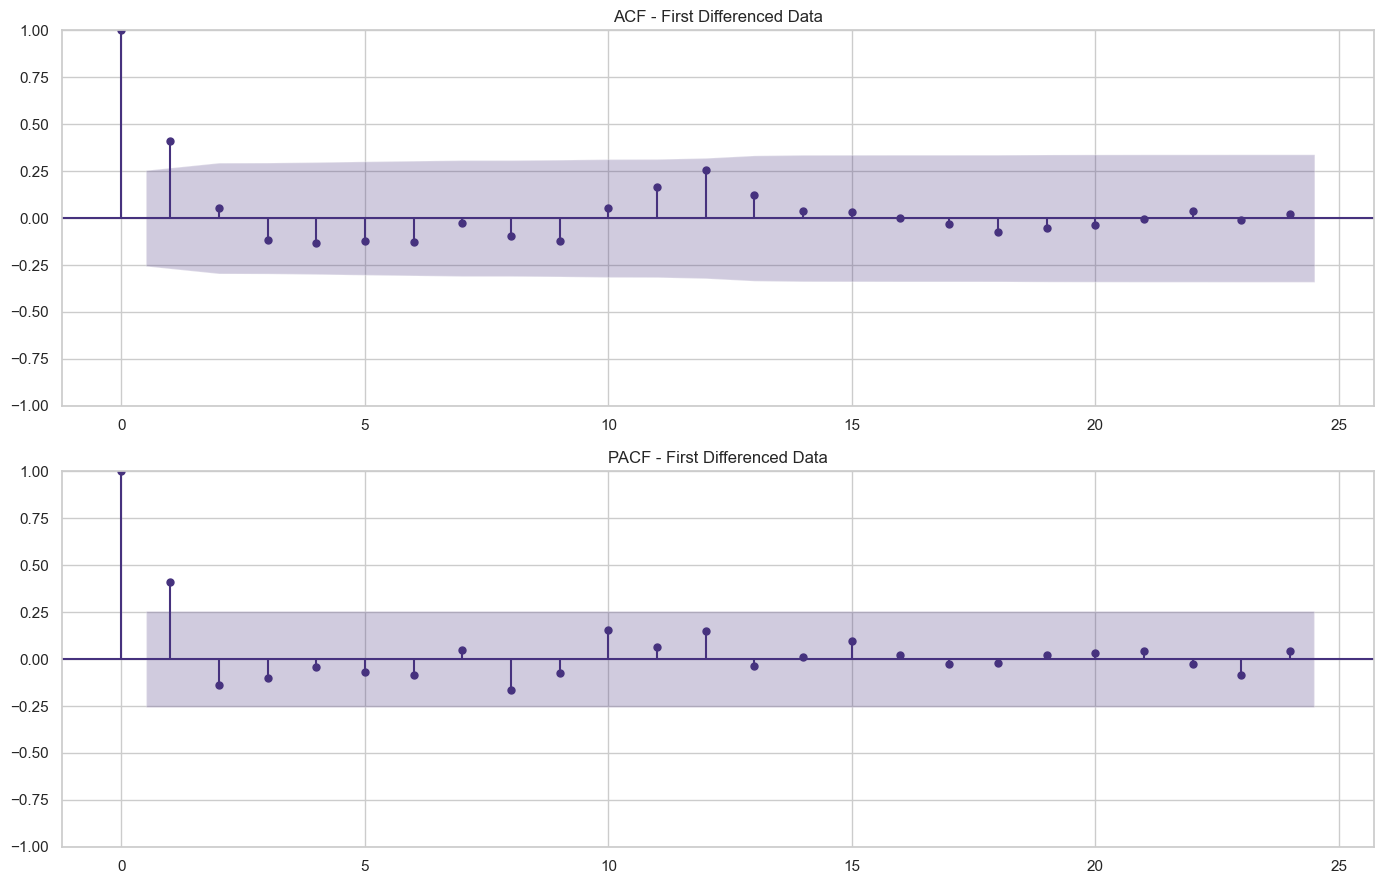

In [46]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# ACF plot
plot_acf(train_diff, lags=24, ax=axes[0])
axes[0].set_title('ACF - First Differenced Data')

# PACF plot
plot_pacf(train_diff, lags=24, ax=axes[1], method='ywm')
axes[1].set_title('PACF - First Differenced Data')

plt.tight_layout()
plt.show()

In [47]:
from statsmodels.tsa.stattools import acf, pacf

acf_values = acf(train_diff, nlags=24)
pacf_values = pacf(train_diff, nlags=24, method='ywm')

confidence_limit = 1.96 / (len(train_diff) ** 0.5)

print("ACF significant lags:")
print([i for i in range(1, 25)
       if abs(acf_values[i]) > confidence_limit])

print("\nPACF significant lags:")
print([i for i in range(1, 25)
       if abs(pacf_values[i]) > confidence_limit])

ACF significant lags:
[1, 12]

PACF significant lags:
[1]


In [48]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Build SARIMA model
model = SARIMAX(
    train,
    order=(1, 1, 0),
    seasonal_order=(0, 0, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Fit model
sarima_result = model.fit(disp=False)

# Display summary
print(sarima_result.summary())

                                      SARIMAX Results                                       
Dep. Variable:             foreign_tourist_arrivals   No. Observations:                   60
Model:             SARIMAX(1, 1, 0)x(0, 0, [1], 12)   Log Likelihood                -604.549
Date:                              Fri, 30 Oct 2026   AIC                           1215.097
Time:                                      21:19:23   BIC                           1220.583
Sample:                                  01-01-2019   HQIC                          1217.152
                                       - 12-01-2023                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3710      0.182      2.036      0.042       0.014       0.728
ma.S.L12       0.25

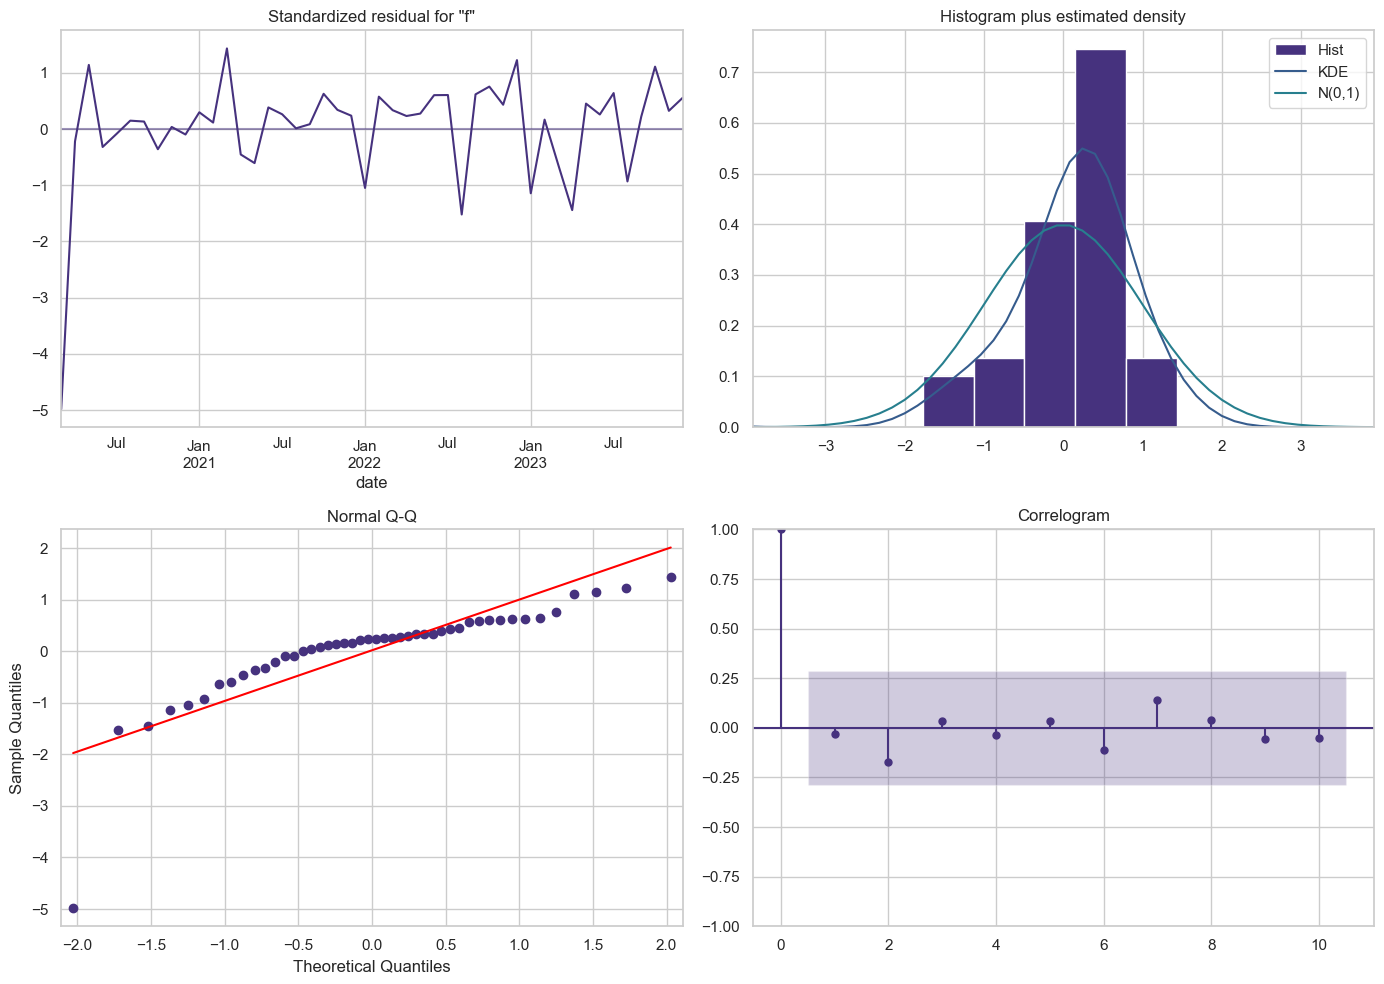

In [49]:
# Generate residual diagnostic plots
sarima_result.plot_diagnostics(figsize=(14, 10))

plt.tight_layout()
plt.show()

In [50]:
from statsmodels.stats.diagnostic import acorr_ljungbox

residuals = sarima_result.resid

lb_test = acorr_ljungbox(
    residuals,
    lags=[12, 24],
    model_df=2,
    return_df=True
)

print(lb_test)

     lb_stat  lb_pvalue
12   4.19509   0.938117
24  14.05972   0.899346


In [51]:
# Convert arrivals into millions
train_scaled = train / 1000000

# Fit the same SARIMA model
scaled_model = SARIMAX(
    train_scaled,
    order=(1, 1, 0),
    seasonal_order=(0, 0, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

scaled_result = scaled_model.fit(disp=False)

print(scaled_result.summary())

                                      SARIMAX Results                                       
Dep. Variable:             foreign_tourist_arrivals   No. Observations:                   60
Model:             SARIMAX(1, 1, 0)x(0, 0, [1], 12)   Log Likelihood                  31.682
Date:                              Fri, 30 Oct 2026   AIC                            -57.364
Time:                                      21:20:29   BIC                            -51.878
Sample:                                  01-01-2019   HQIC                           -55.309
                                       - 12-01-2023                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3992      0.228      1.750      0.080      -0.048       0.846
ma.S.L12       0.61

In [52]:
# Forecast next 12 months
forecast_result = scaled_result.get_forecast(steps=12)

# Predicted values (convert millions back to actual counts)
predictions = forecast_result.predicted_mean * 1000000

# Confidence intervals
confidence_intervals = forecast_result.conf_int() * 1000000

# Display predictions
forecast_df = pd.DataFrame({
    'Actual': test,
    'Predicted': predictions
})

print(forecast_df)

             Actual     Predicted
2024-01-01   981609  1.094371e+06
2024-02-01  1032301  1.096867e+06
2024-03-01   893021  1.085932e+06
2024-04-01   672684  9.642597e+05
2024-05-01   622189  9.350523e+05
2024-06-01   722615  9.313913e+05
2024-07-01   799842  9.663673e+05
2024-08-01   661322  9.478863e+05
2024-09-01   691247  9.437343e+05
2024-10-01   840330  1.013110e+06
2024-11-01   973941  1.055321e+06
2024-12-01  1060621  1.083892e+06


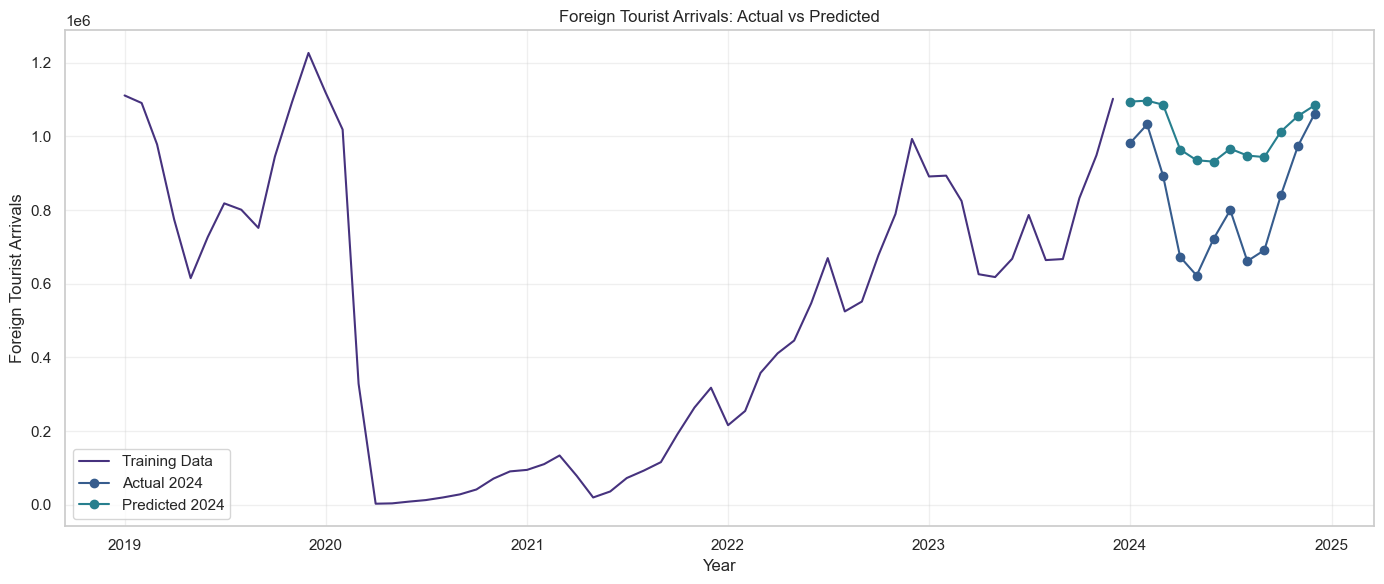

In [53]:
plt.figure(figsize=(14, 6))

plt.plot(train.index, train, label='Training Data')
plt.plot(test.index, test, label='Actual 2024', marker='o')
plt.plot(predictions.index, predictions,
         label='Predicted 2024', marker='o')

plt.title('Foreign Tourist Arrivals: Actual vs Predicted')
plt.xlabel('Year')
plt.ylabel('Foreign Tourist Arrivals')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [54]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)
import numpy as np

mae = mean_absolute_error(test, predictions)

rmse = np.sqrt(mean_squared_error(test, predictions))

mape = mean_absolute_percentage_error(
    test, predictions
) * 100

print("Forecast Evaluation")
print("-------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

Forecast Evaluation
-------------------
MAE: 180538.48
RMSE: 202320.41
MAPE: 24.47 %


In [55]:
# Seasonal naive forecast
baseline_predictions = train.iloc[-12:].copy()
baseline_predictions.index = test.index

baseline_mae = mean_absolute_error(
    test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(test, baseline_predictions)
)

baseline_mape = mean_absolute_percentage_error(
    test, baseline_predictions
) * 100

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))
print("Baseline MAPE:", round(baseline_mape, 2), "%")

Baseline MAE: 43253.83
Baseline RMSE: 58173.06
Baseline MAPE: 4.89 %


In [56]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error
import numpy as np
import pandas as pd

# Candidate SARIMA models
candidates = {
    'SARIMA_1': ((1, 1, 0), (0, 0, 1, 12)),
    'SARIMA_2': ((1, 1, 0), (0, 1, 1, 12)),
    'SARIMA_3': ((0, 1, 1), (0, 1, 1, 12)),
    'SARIMA_4': ((1, 1, 1), (0, 1, 1, 12)),
}

results = []

for name, (order, seasonal_order) in candidates.items():

    try:
        model = SARIMAX(
            train_scaled,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted_model = model.fit(disp=False)

        forecast = (
            fitted_model.get_forecast(steps=12)
            .predicted_mean * 1000000
        )

        mae_value = mean_absolute_error(test, forecast)

        rmse_value = np.sqrt(
            mean_squared_error(test, forecast)
        )

        mape_value = mean_absolute_percentage_error(
            test, forecast
        ) * 100

        results.append({
            'Model': name,
            'Order': str(order),
            'Seasonal Order': str(seasonal_order),
            'AIC': fitted_model.aic,
            'MAE': mae_value,
            'RMSE': rmse_value,
            'MAPE': mape_value
        })

    except Exception as e:
        print(name, "failed:", e)

comparison_df = pd.DataFrame(results)

print(comparison_df.round(2).to_string(index=False))

   Model     Order Seasonal Order     AIC       MAE      RMSE  MAPE
SARIMA_1 (1, 1, 0)  (0, 0, 1, 12)  -57.36 180538.48 202320.41 24.47
SARIMA_2 (1, 1, 0)  (0, 1, 1, 12) 1221.64  55328.15  63884.34  6.92
SARIMA_3 (0, 1, 1)  (0, 1, 1, 12) 1271.09  62652.37  71218.70  7.89
SARIMA_4 (1, 1, 1)  (0, 1, 1, 12) 1051.86  63220.49  71778.36  7.96


In [57]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

ets_models = {
    'Holt_Winters_Additive': {
        'trend': 'add',
        'seasonal': 'add'
    },
    'Holt_Winters_Multiplicative': {
        'trend': 'add',
        'seasonal': 'mul'
    }
}

ets_results = []

for name, params in ets_models.items():

    model = ExponentialSmoothing(
        train_scaled,
        trend=params['trend'],
        seasonal=params['seasonal'],
        seasonal_periods=12,
        initialization_method='estimated'
    )

    fitted = model.fit(optimized=True)

    forecast = fitted.forecast(12) * 1000000

    mae_value = mean_absolute_error(test, forecast)

    rmse_value = np.sqrt(
        mean_squared_error(test, forecast)
    )

    mape_value = mean_absolute_percentage_error(
        test, forecast
    ) * 100

    ets_results.append({
        'Model': name,
        'MAE': mae_value,
        'RMSE': rmse_value,
        'MAPE': mape_value
    })

ets_comparison = pd.DataFrame(ets_results)

print(ets_comparison.round(2).to_string(index=False))

                      Model       MAE      RMSE  MAPE
      Holt_Winters_Additive 146856.41 165630.58 18.86
Holt_Winters_Multiplicative 294201.47 327963.73 37.06


In [58]:
# Final selected model: Seasonal Naive

final_predictions = train.iloc[-12:].copy()
final_predictions.index = test.index

final_results = pd.DataFrame({
    'Actual_Arrivals': test,
    'Predicted_Arrivals': final_predictions
})

final_results['Absolute_Error'] = abs(
    final_results['Actual_Arrivals'] -
    final_results['Predicted_Arrivals']
)

final_results['Percentage_Error'] = (
    final_results['Absolute_Error'] /
    final_results['Actual_Arrivals']
) * 100

print(final_results.round(2))

# Save results
final_results.to_csv(
    'final_tourism_forecast_results.csv'
)

            Actual_Arrivals  Predicted_Arrivals  Absolute_Error  \
date                                                              
2024-01-01           981609              891084           90525   
2024-02-01          1032301              893352          138949   
2024-03-01           893021              824549           68472   
2024-04-01           672684              625772           46912   
2024-05-01           622189              618086            4103   
2024-06-01           722615              667720           54895   
2024-07-01           799842              786486           13356   
2024-08-01           661322              664155            2833   
2024-09-01           691247              666946           24301   
2024-10-01           840330              832233            8097   
2024-11-01           973941              948631           25310   
2024-12-01          1060621             1101914           41293   

            Percentage_Error  
date                          

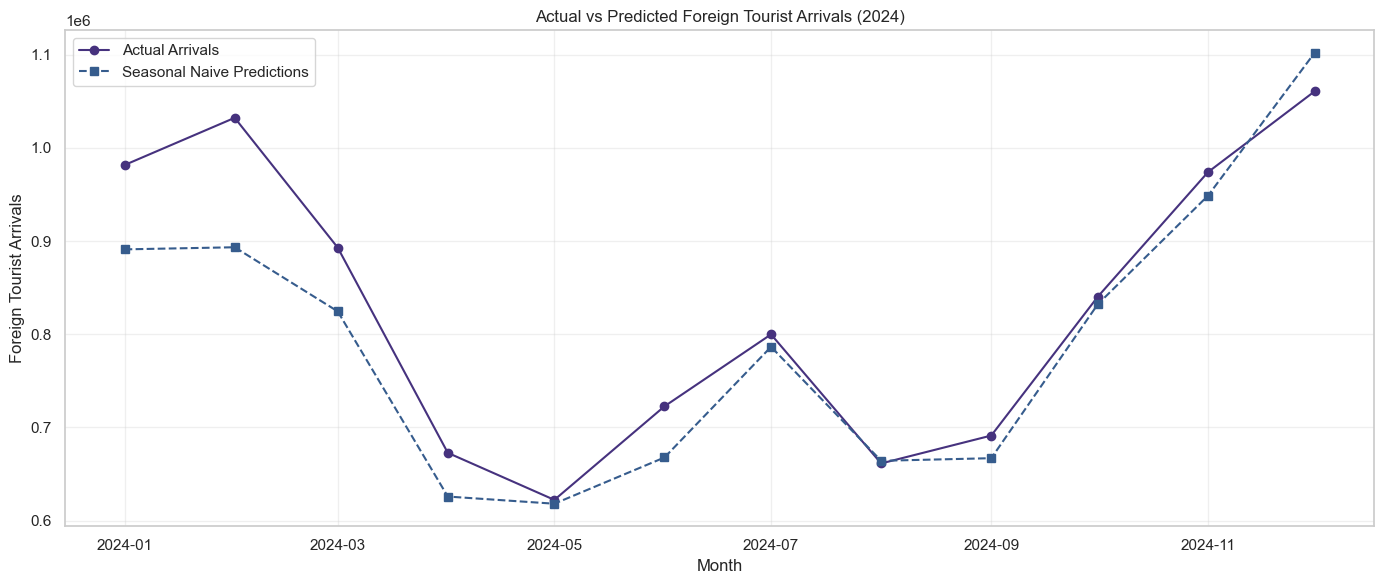

In [59]:
plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test,
    marker='o',
    label='Actual Arrivals'
)

plt.plot(
    final_predictions.index,
    final_predictions,
    marker='s',
    linestyle='--',
    label='Seasonal Naive Predictions'
)

plt.title('Actual vs Predicted Foreign Tourist Arrivals (2024)')
plt.xlabel('Month')
plt.ylabel('Foreign Tourist Arrivals')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
final_metrics = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'MAPE'],
    'Seasonal_Naive': [
        baseline_mae,
        baseline_rmse,
        baseline_mape
    ],
    'SARIMA_Best': [
        55328.15,
        63884.34,
        6.92
    ]
})

print(final_metrics.round(2))

  Metric  Seasonal_Naive  SARIMA_Best
0    MAE        43253.83     55328.15
1   RMSE        58173.06     63884.34
2   MAPE            4.89         6.92
